# Feature creation

Are the decision features complete, and what did they cost? Every decision model answers the same frozen requests (notebook 1); its probabilities are stored once per dataset in `data/jev_cache/<dataset>.sqlite3` with provider, checkpoint, question and representation identities. This notebook reads local stores and manifests only; it dispatches nothing. Benchmark-readiness (feature identities, PCA, predictor runtimes) is qualified in notebook 3 (0B).

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
import pandas as pd
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.visualize import figures, style
style.apply()

import json
from src.utils import paths
from src.utils.config import load_config, save_resolved_config
from src.evaluation import study_audit
NOTEBOOK = "general/2_feature_creation"
begin_report()
report_section("1. Scope and provenance")
save = figures.FigureSaver(NOTEBOOK)
cfg = load_config("feature_creation")
save_resolved_config(cfg, NOTEBOOK)
display_json("Execution provenance", provenance())

## Decision-feature store completeness

Which of the 17 decision models × 18 datasets × 2 request views are complete? A view counts when a complete feature artifact is in the local dataset store or listed in a compact feature-creation manifest. Jev runs under a fixed per-dataset allocation (EUR 5 in total), so most of its datasets hold recorded requests but no complete artifact. White cells mean no local evidence, not a failed extraction.

status,provider,observed,partial,unknown
,cloudflare,36,0,0
,decision3,36,0,0
,drex_max,0,0,36
,glide,0,0,36
,h2o,36,0,0
,intern,36,0,0
,jev,2,34,0
,kev,36,0,0
,knowline,0,0,36
,liquid,36,0,0


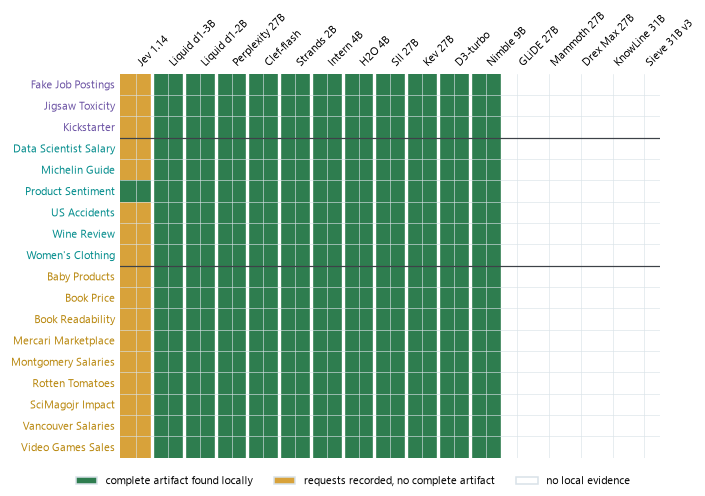

In [2]:
report_section("2. Decision-feature store completeness")
from src.visualize.audit import feature_store_figure
spend = study_audit.jev_spend()
store = study_audit.feature_store_status(partial={("jev", d) for d in spend.dataset_id})
display_table("Completeness per decision model (dataset-views)", store.pivot_table(index="provider", columns="status", values="dataset_id", aggfunc="count", fill_value=0).reset_index(), preview_rows=17)
record(store, "Feature-store status per dataset, decision model and view")
fig, name, caption = feature_store_figure(store)
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)

## Extraction compute

What does one decision model cost to run? GPU-hours per 1,000 distinct requests come from the timing manifests of the feature-creation jobs (inference wall time on one B200, without loading, staging or publication); the Slurm compute ledger adds whole-job rates when it is present locally. Every open-weight model answers the same distinct requests (0A token audit), so rates are directly comparable. Jev is a hosted API: its recorded charges are shown against the owner-approved ceiling.

Compute ledger: waiting for output_JEVPFN/compute_ledger.json (src.cluster.compute_ledger on VSC)


model_id,kind,distinct_requests,timed_requests,timed_datasets,inference_gpu_hours,inference_gpu_hours_per_1000,ledger_gpu_hours_per_1000
jev,hosted,NaN,NaN,0,NaN,NaN,NaN
liquid,decision,1698127.0,1697677.0,18,4.07326,0.00240,NaN
liquid_lfm3,decision,1698127.0,NaN,0,NaN,NaN,NaN
perplexity,decision,1698127.0,849068.0,18,21.19270,0.02496,NaN
cloudflare,decision,1698127.0,849068.0,18,15.74026,0.01854,NaN
strands,decision,1698127.0,1630686.0,18,12.23777,0.00750,NaN
intern,decision,1698127.0,1698127.0,18,18.52811,0.01091,NaN
h2o,decision,1698127.0,1698127.0,18,18.19118,0.01071,NaN
sii,decision,1698127.0,1698127.0,18,42.40876,0.02497,NaN
kev,decision,1698127.0,NaN,0,NaN,NaN,NaN


dataset_id,jobs,completed,unresolved,spent_usd,reserved_usd,allocation_usd
BIN_TEXT_FAKE_JOB_POSTING,9596,9595,1,0.2869,0.0000,0.3056
BIN_TEXT_JIGSAW_TOXICITY,12059,12058,1,0.2897,0.0000,0.3056
BIN_TEXT_KICKSTARTER_FUNDING,12504,12503,1,0.2890,0.0000,0.3056
MUL_TEXT_DATA_SCIENTIST_SALARY,7416,7415,1,0.2921,0.0000,0.3056
MUL_TEXT_MICHELIN_RESTAURANTS,7891,7890,1,0.2897,0.0000,0.3056
MUL_TEXT_PRODUCT_SENTIMENT,5088,5088,0,0.1449,0.0000,0.3056
MUL_TEXT_US_ACCIDENTS,9601,9600,1,0.2914,0.0000,0.3056
MUL_TEXT_WINE_REVIEW,3701,3700,1,0.2885,0.0000,0.3056
MUL_TEXT_WOMEN_CLOTHING_REVIEW,9084,9083,1,0.2843,0.0000,0.3056
REG_TEXT_BABIES_PRICES,9395,9394,1,0.2854,0.0000,0.3056


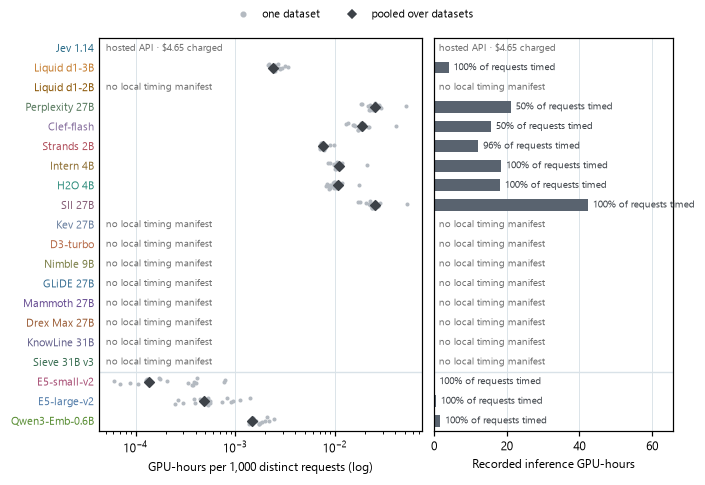

In [3]:
report_section("3. Extraction compute and Jev spending")
from src.visualize.build_review import extraction_figure
timings = study_audit.inference_timings()
token_audit = json.loads((paths.manifests_dir("experiment_0") / "before_extraction" / "token_audit.json").read_text(encoding="utf-8"))
ledger = study_audit.read_compute_ledger()
print("Compute ledger:", "present" if ledger else "waiting for output_JEVPFN/compute_ledger.json (src.cluster.compute_ledger on VSC)")
texts = int(timings[timings.kind.eq("encoder")].groupby("model_id").requests.sum().max()) if (timings.kind == "encoder").any() else None
workload = study_audit.extraction_workload(timings, token_audit=token_audit, ledger=ledger, distinct_texts=texts)
budget = study_audit.jev_budget(spend)
display_table("Extraction compute per decision model and encoder", workload.round(5), preview_rows=20)
display_json("Jev recorded charges against the ceiling", budget)
display_table("Jev charges per dataset", spend.round(4), preview_rows=18)
record(study_audit.dataset_rates(timings), "GPU-hours per 1,000 requests per model and dataset")
fig, name, caption = extraction_figure(workload, study_audit.dataset_rates(timings), jev_charges=budget["recorded_charges_usd"])
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)

## Predictor input widths

How wide is each arm the predictors receive? Widths are the same for every decision model (1 feature per request for binary, K for multiclass, 9 for regression) and for every encoder; each arm also carries one missing-text flag per text column. All arms run on all seven predictors: Kumo's 500-column default recipe is widened where an arm is wider (owner-approved 23-11-2026). Width does not establish GPU or full-fold feasibility (0B).

Audit: Fake Job Postings


Audit: Jigsaw Toxicity


Audit: Kickstarter


Audit: Data Scientist Salary


Audit: Michelin Guide


Audit: Product Sentiment


... (11 outputs left out)

Audit: Vancouver Salaries


Audit: Video Games Sales


Audit: Zomato Restaurants

configuration,feature_set,Non-text,Embedding / PCA,Joint,Per-column
Non-text,non_text,True,False,False,False
+ Joint,non_text_plus_joint,True,False,True,False
+ Per-column,non_text_plus_per_column,True,False,False,True
+ Both,non_text_plus_both,True,False,True,True
+ Embedding,non_text_plus_frozen_e5,True,True,False,False


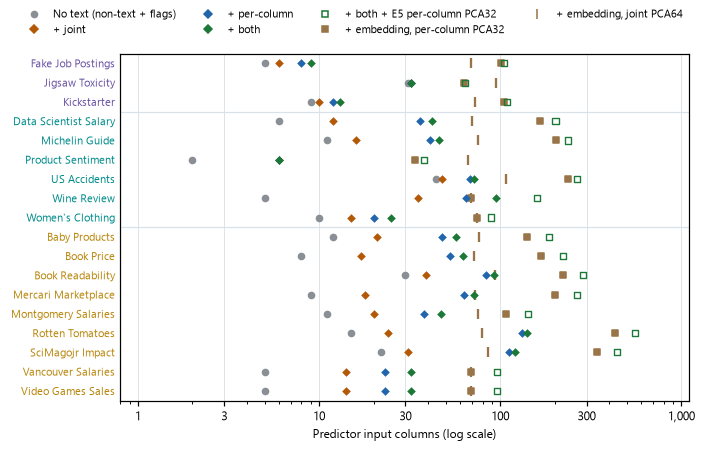

dataset,dataset_id,text_columns,non_text_columns,joint_probabilities,per_column_probabilities,both_probabilities,kumo_conservative_max
Baby Products,REG_TEXT_BABIES_PRICES,4,8,21,48,57,65
Book Price,REG_TEXT_BOOK_PRICE,5,3,17,53,62,65
Book Readability,REG_TEXT_BOOK_READABILITY,6,24,39,84,93,117
Mercari Marketplace,REG_TEXT_MERCARI_MARKETPLACE,6,3,18,63,72,75
Montgomery Salaries,REG_TEXT_MONTGOMERY_SALARIES,3,8,20,38,47,55
Rotten Tomatoes,REG_TEXT_ROTTEN_TOMATOES,13,2,24,132,141,143
SciMagojr Impact,REG_TEXT_SCIMAGOJR_IMPACT,10,12,31,112,121,133
Vancouver Salaries,REG_TEXT_VANCOUVER_SALARIES,2,3,14,23,32,35
Video Games Sales,REG_TEXT_VIDEO_GAMES_SALES,2,3,14,23,32,35


In [4]:
report_section("4. Predictor input widths")
from src.data.audit import audit_collection
from src.evaluation.campaign import benchmark_plan
from src.evaluation.features import benchmark_feature_table
from src.evaluation.widths import pca_width_table
from src.evaluation.research_questions import regression_width_table
from src.evaluation.notebook_evidence import study_grid
from src.visualize.feature_design import predictor_width_figure
audit = audit_collection(cfg)
selected = audit.summary[~audit.summary.dataset_id.isin(cfg["dataset_selection"]["exclude"])]
benchmark = pd.DataFrame(benchmark_plan())
display_local(benchmark_feature_table())
fig, name, caption = predictor_width_figure(benchmark, selected)
save(fig, name, caption=caption)
display_local(fig)
plt.close(fig)
display_table("Regression widths including availability flags", regression_width_table(), preview_rows=9)
record(benchmark.groupby(["phase", "feature_set"], dropna=False).size().rename("configurations").reset_index(), "Benchmark configurations per phase and feature set")
record(pca_width_table(), "All dataset PCA widths including non-text and missing indicators")
record(study_grid(benchmark.to_dict("records")), "Planned grid totals")

## Storage contract

One permanent file per dataset holds raw responses (one per exact request and version), row links (`csv:N` with the dataset fingerprint), compressed feature tables with immutable manifests, and the dataset identity. Missing inputs have missing features and no request key.

In [5]:
report_section("5. Storage contract")
from src.jev.features import table_schemas
record(table_schemas(), "Logical file and table contracts")
record({"per_dataset_store": "data/jev_cache/<dataset_id>.sqlite3", "shared_questions": "data/decision_inputs/<dataset_id>.sqlite3",
        "logs": str(paths.logs_dir("feature_creation")), "manifests": str(paths.manifests_dir("feature_creation"))}, "Locations")

## Complete report

In [6]:
finish_report(NOTEBOOK, save.summary() + "\nOnly local stores, manifests and configuration were read; no inference, model training or live VSC changes were performed.")

general/2_feature_creation

1. Scope and provenance


Execution provenance
{
  "code_sha256": "ae47342a8c0ecd61ac29f160dd195690d8ecfe067a26ce4bb59cd7091e41ba9d",
  "git_head": "c0eae19b07a79d71cf6ea82f82bd3995d127dd37",
  "git_dirty": true,
  "tfm_library_pin": "4574eea0c2ce6646b5d2e9c7f53a6ef3882c368c dm-library (remotes/origin/HEAD)\n 248f137046487e0d57360abba1e060420ae54e1a tfm-library (remotes/origin/HEAD)\n 2208cf68d6351eff2cb0ddb5a9eb1d822523457b vsc-library (heads/main-8-g2208cf6)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.4",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


2. Decision-feature store completeness


Completeness per decision model (dataset-views)
   provider  observed  partial  unknown
 cloudflare        36        0        0
  decision3        36        0        0
   drex_max         0        0       36
      glide         0        0       36
        h2o        36        0        0
    